In [5]:

# ============================================================================
# Figure 16 - Cell 1
# Read CFD histories for all three missions; no 1D model input
# Short: 50 km, Baseline: 100 km, Long: 120 km
# Ambient temperature: 25 degC
# ============================================================================

import os
import re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

# ============================================================================
# 1. Configuration
# ============================================================================

PROJECT_ROOT = Path(os.environ.get('EBATS_ROOT', r'D:\eBATS'))
DATA_DIR = PROJECT_ROOT / 'data'
OUTPUT_DIR = PROJECT_ROOT / 'out' / 'C0010'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

AMBIENT_C = 25.0
DT = 1.0
NUM_STEPS = 1920

STAGE_LABELS = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']

STAGE_NAMES = [
    'Take-off',
    'Ascent transition',
    'Acceleration',
    'Cruise',
    'Deceleration',
    'Descent transition',
    'Hovering',
    'Landing'
]

FIG16_MISSIONS = [
    {'key': 'short', 'name': 'Short-cruise / extended-hover (50 km)', 'folder': 'M050km_C0633s_H0300s_D1293s', 'cruise': 633, 'hover': 300, 'end': 1293},
    {'key': 'baseline', 'name': 'Baseline mission (100 km)', 'folder': 'M100km_C1380s_H0180s_D1920s', 'cruise': 1380, 'hover': 180, 'end': 1920},
    {'key': 'long', 'name': 'Long-cruise / normal-hover (120 km)', 'folder': 'M120km_C1680s_H0180s_D2220s', 'cruise': 1680, 'hover': 180, 'end': 2220}
]

for mission in FIG16_MISSIONS:
    mission['stage_bounds'] = np.r_[0.0, np.cumsum([6, 30, 144, mission['cruise'], 144, 30, mission['hover'], 6])]

    if not np.isclose(mission['stage_bounds'][-1], mission['end']):
        raise ValueError(f'Stage durations inconsistent with mission: {mission["name"]}')

# ============================================================================
# 2. Find CFD temperature files
# ============================================================================

# M: mission distance, C: cruise, H: hovering, D: total duration.
# Populated temperature folders use T020C/T025C/T035C and max.out/min.out.
# The two empty LC baseline folders are preserved and may be completed later.
SKIPPABLE_CFD_CASES = {
    ('LC', 'M100km_C1380s_H0180s_D1920s', 20),
    ('LC', 'M100km_C1380s_H0180s_D1920s', 35),
}


def cfd_report_paths(cooling, mission_folder, ambient):
    ambient = int(ambient)
    base = DATA_DIR / 'C0010' / cooling / mission_folder
    if not base.is_dir():
        raise FileNotFoundError(f'Missing CFD mission directory: {base}')
    folder = base / f'T{ambient:03d}C'
    files = (folder / 'max.out', folder / 'min.out')
    if all(path.is_file() for path in files):
        return files
    if (cooling, mission_folder, ambient) in SKIPPABLE_CFD_CASES:
        candidates = [folder, base / f'{ambient}℃', base / f'{ambient}°C', base / str(ambient)]
        present = [path for path in candidates if path.is_dir()]
        if not present or all(not any(path.iterdir()) for path in present):
            print(f'[SKIP empty CFD] {cooling}, {mission_folder}, {ambient} degC')
            return None
    raise FileNotFoundError(
        f'Expected a complete CFD max.out/min.out pair in {folder}. '
        'Only the two declared empty LC 100-km cases may be skipped.'
    )


def find_cfd_file(cooling, mission, side):
    files = cfd_report_paths(cooling, mission['folder'], AMBIENT_C)
    if files is None:
        raise FileNotFoundError(f'Figure 16 requires the 25-C CFD history for {cooling}/{mission["key"]}.')
    return files[0 if side == 'max' else 1]


# ============================================================================
# 3. Read complete Fluent temperature histories
# ============================================================================

def read_fluent_temperature(path, metric, mission_end):

    path = Path(path)
    lines = path.read_text(encoding='utf-8-sig', errors='replace').splitlines()
    rows, headers = [], []

    for line in lines:
        values_text = re.split(r'[\s,]+', line.strip().strip('()[]'))

        if len(values_text) < 2:
            continue

        try:
            values = [float(v.replace('D', 'E').replace('d', 'e')) for v in values_text]
        except ValueError:
            continue

        if np.all(np.isfinite(values)):
            rows.append(values)

    if len(rows) < 10:
        raise ValueError(f'Not enough Fluent numerical records in {path}')

    ncols = Counter(map(len, rows)).most_common(1)[0][0]
    data = np.array([row for row in rows if len(row) == ncols], dtype=float)

    def normalize(name):
        return re.sub(r'[^a-z0-9]+', '-', name.lower()).strip('-')

    for line in lines[:80]:
        names = re.findall(r'"([^"\n]+)"', line)

        if len(names) == ncols:
            names = [normalize(s) for s in names]
            quality = 3 * any('flow-time' in s for s in names) + 2 * any(s == metric or s.endswith('-' + metric) for s in names)
            headers.append((quality, names))

    names = max(headers, key=lambda item: item[0])[1] if headers else []
    flow_names = ('flow-time', 'flowtime', 'physical-time', 'time', 'time-s', 'time-sec')

    time_col = next((i for i, s in enumerate(names) if s in flow_names), None)
    temp_col = next((i for i, s in enumerate(names) if s == metric or s.endswith('-' + metric)), None)

    def get_celsius(j):
        values = data[:, j]
        return values - 273.15 if np.median(values) > 180 else values

    def valid_temperature(j):
        values = get_celsius(j)
        return np.all(np.isfinite(values)) and -40 < np.min(values) and np.max(values) < 130 and abs(float(values[0]) - AMBIENT_C) < 8

    def valid_time(j):
        values = data[:, j]
        return np.all(np.isfinite(values)) and -1 <= values[0] <= 2 and abs(float(values[-1]) - mission_end) <= 5 and np.mean(np.diff(values) >= -1e-9) > 0.995

    if temp_col is None or not valid_temperature(temp_col):
        candidates = [j for j in range(ncols) if j != time_col and valid_temperature(j)]

        if not candidates:
            raise ValueError(f'Cannot identify the {metric} temperature column: {path}; header={names}')

        temp_col = min(candidates, key=lambda j: abs(float(get_celsius(j)[0]) - AMBIENT_C))

    if time_col is None or time_col == temp_col or not valid_time(time_col):
        candidates = [j for j in range(ncols) if j != temp_col and valid_time(j)]

        if not candidates:
            raise ValueError(f'Cannot identify the physical time column: {path}; header={names}')

        time_col = min(candidates, key=lambda j: abs(float(data[-1, j]) - mission_end))

    time = data[:, time_col].copy()
    temperature = get_celsius(temp_col).copy()

    mask = np.isfinite(time) & np.isfinite(temperature) & (time >= 0) & (time <= mission_end + 1)
    time, temperature = time[mask], temperature[mask]

    order = np.argsort(time, kind='stable')
    time, temperature = time[order], temperature[order]

    _, reverse_idx = np.unique(time[::-1], return_index=True)
    keep = np.sort(len(time) - 1 - reverse_idx)
    time, temperature = time[keep], temperature[keep]

    if len(time) < 100 or time[0] > 2 or abs(time[-1] - mission_end) > 5:
        raise ValueError(f'Incomplete CFD history: {path}; samples={len(time)}, duration={time[0]:.1f}..{time[-1]:.1f} s')

    print(f'[CFD] {path} | N={len(time)}, time column={time_col + 1}, {metric} column={temp_col + 1}, Tmax={temperature.max():.3f} C')

    return time, temperature



# Assemble all six CFD histories at 25 degC.
FIG16_DATA = {}

SUMMARY = []

for mission in FIG16_MISSIONS:

    for cooling in ('AC', 'LC'):

        high_report = read_fluent_temperature(find_cfd_file(cooling, mission, 'max'), 'max', mission['end'])
        low_report = read_fluent_temperature(find_cfd_file(cooling, mission, 'min'), 'min', mission['end'])
        time = np.union1d(high_report[0], low_report[0])
        time = time[(time >= max(high_report[0][0], low_report[0][0]))
                    & (time <= min(high_report[0][-1], low_report[0][-1]))]
        high = np.interp(time, high_report[0], high_report[1])
        low = np.interp(time, low_report[0], low_report[1])
        source = 'CFD'

        delta = high - low

        if len(time) < 100 or abs(time[-1] - mission['end']) > 5 or np.min(delta) < -0.1:
            raise ValueError(f'Invalid temperature history: {cooling}, {mission["name"]}')

        FIG16_DATA[(mission['key'], cooling)] = {
            'time_s': np.asarray(time),
            'Tmax_C': np.asarray(high),
            'Tmin_C': np.asarray(low),
            'DT_C': np.asarray(delta),
            'source': source
        }

        SUMMARY.append({
            'Mission': mission['name'],
            'Cooling': cooling,
            'Source': source,
            'Tmax_C': float(np.max(high)),
            'DTmax_C': float(np.max(delta))
        })


        print(f'[DONE] {mission["key"]:8s} {cooling}: Tmax={np.max(high):.3f} C, DTmax={np.max(delta):.3f} C, N={len(time)}')


FIG16_TABLE = pd.DataFrame(SUMMARY)

print('\n=== Figure 16: Six thermal histories ===')
print(FIG16_TABLE.to_string(index=False, float_format=lambda v: f'{v:.3f}'))



[CFD] D:\eBATS\data\C0010\AC\M050km_C0633s_H0300s_D1293s\T025C\max.out | N=1294, time column=3, max column=2, Tmax=50.327 C
[CFD] D:\eBATS\data\C0010\AC\M050km_C0633s_H0300s_D1293s\T025C\min.out | N=1294, time column=3, min column=2, Tmax=42.297 C
[DONE] short    AC: Tmax=50.327 C, DTmax=8.059 C, N=1294
[CFD] D:\eBATS\data\C0010\LC\M050km_C0633s_H0300s_D1293s\T025C\max.out | N=1294, time column=3, max column=2, Tmax=39.380 C
[CFD] D:\eBATS\data\C0010\LC\M050km_C0633s_H0300s_D1293s\T025C\min.out | N=1294, time column=3, min column=2, Tmax=35.211 C
[DONE] short    LC: Tmax=39.380 C, DTmax=4.180 C, N=1294
[CFD] D:\eBATS\data\C0010\AC\M100km_C1380s_H0180s_D1920s\T025C\max.out | N=1921, time column=3, max column=2, Tmax=44.316 C
[CFD] D:\eBATS\data\C0010\AC\M100km_C1380s_H0180s_D1920s\T025C\min.out | N=1921, time column=3, min column=2, Tmax=39.412 C
[DONE] baseline AC: Tmax=44.316 C, DTmax=4.932 C, N=1921
[CFD] D:\eBATS\data\C0010\LC\M100km_C1380s_H0180s_D1920s\T025C\max.out | N=1921, time

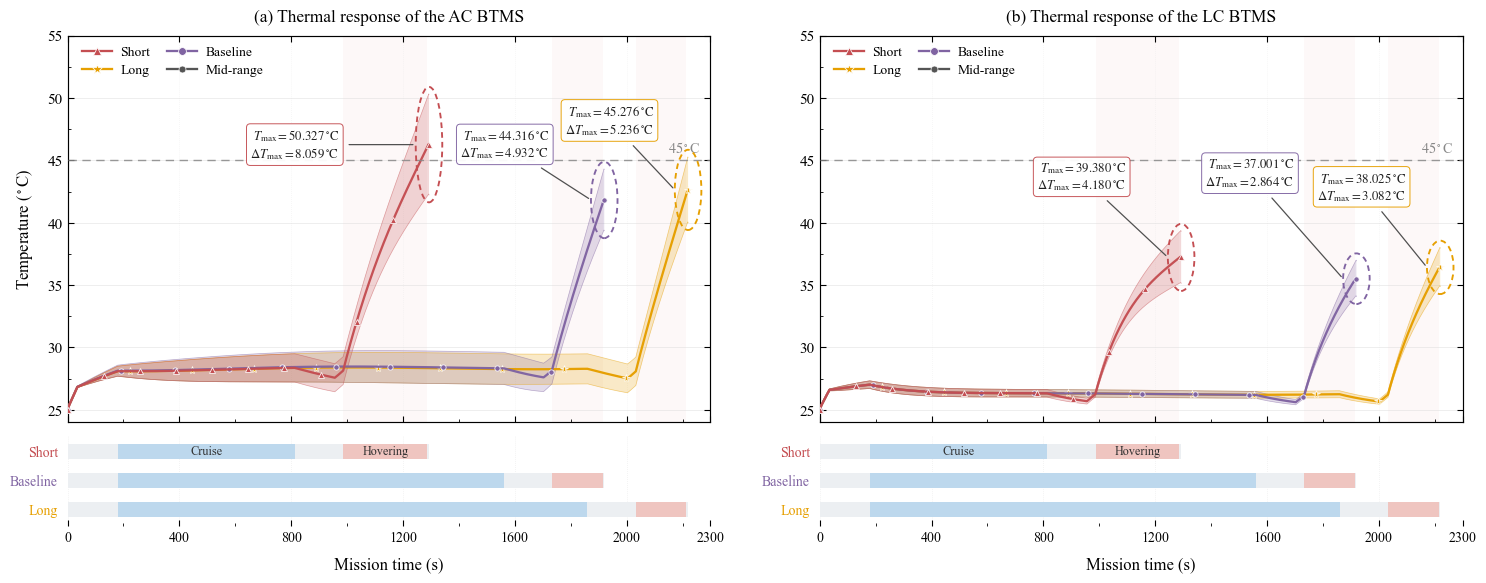


Mission-level thermal performance:
--------------------------------------------------------------------------------------------------------------
Mission      Cooling      Tmax (C)    DTmax (C)     DT time    DT upper    DT lower
--------------------------------------------------------------------------------------------------------------
short        AC             50.327        8.059      1293.0      50.292      42.233
short        LC             39.380        4.180      1293.0      39.311      35.131
baseline     AC             44.316        4.932      1920.0      44.293      39.361
baseline     LC             37.001        2.864      1920.0      36.943      34.078
long         AC             45.276        5.236      2220.0      45.250      40.014
long         LC             38.025        3.082      2220.0      37.962      34.880

PNG: D:\eBATS\out\C0010\C0010R00_PARK25_ACLC_INTG_CFD_CMP_mission_thermal_response.png
PDF: D:\eBATS\out\C0010\C0010R00_PARK25_ACLC_INTG_CFD_CMP_mission_

In [6]:

# =============================================================================
# Figure 16 | Transient battery temperature under three flight missions
# Two panels: (a) AC | (b) LC
# Temperature envelopes + maximum temperature-difference ellipse callouts
# Compact four-item legends in both panels + simplified flight-stage timelines
# =============================================================================

# =============================================================================
# 1. Import libraries and configure plotting
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
from matplotlib.ticker import AutoMinorLocator

FIGURE_NAME = 'C0010R00_PARK25_ACLC_INTG_CFD_CMP_mission_thermal_response'
OUTPUT_DIR = Path(r'D:\eBATS\out\C0010')
PAPER_IMAGE_DIR = Path(r'D:\Workspace\Paper_eBATS\images')
DPI = 900

MISSION_ORDER = ('short', 'baseline', 'long')
DRAW_ORDER = ('long', 'baseline', 'short')
COOLING_ORDER = ('AC', 'LC')

# =============================================================================
# 1.1 Mission colors and markers
# =============================================================================

MISSION_COLORS = {
    'short': '#C44E52',
    'baseline': '#8064A2',
    'long': '#E69F00'
}

MISSION_LABELS = {
    'short': 'Short-cruise / extended-hover (50 km)',
    'baseline': 'Baseline mission (100 km)',
    'long': 'Long-cruise / normal-hover (120 km)'
}

MISSION_MARKERS = {
    'short': '^',
    'baseline': 'o',
    'long': '*'
}

# Temperature envelope
BAND_ALPHA = 0.22
BAND_EDGE_LINEWIDTH = 0.50
BAND_EDGE_ALPHA = 0.50

# Mid-range temperature line
MIDLINE_LINEWIDTH = 1.65
MIDLINE_ALPHA = 0.98

# Mission marker sizes
MARKER_SIZE = {
    'short': 4.2,
    'baseline': 3.8,
    'long': 5.8
}

MARKER_EDGE_WIDTH = 0.55
MARKER_COUNT = 11

# =============================================================================
# 1.2 Flight-stage colors and label settings
# =============================================================================

CRUISE_COLOR = '#BBD7ED'
HOVER_COLOR = '#F0C3BE'
OTHER_STAGE_COLOR = '#ECEFF2'

MAIN_HOVER_ALPHA = 0.10
STAGE_BAR_HEIGHT = 0.54
STAGE_CRUISE_ALPHA = 0.95
STAGE_HOVER_ALPHA = 0.95

# True = colored mission names; False = black mission names
STAGE_LABEL_USE_MISSION_COLOR = True
STAGE_LABEL_DEFAULT_COLOR = '#202020'

# Only show Cruise / Hovering names on the Short mission row
SHOW_STAGE_NAMES_ON_SHORT = True
STAGE_NAME_FONTSIZE = 8.8
STAGE_NAME_COLOR = '#303030'

# Thermal constraints
TEMP_DESIGN_LIMIT = 45.0
DT_DESIGN_LIMIT = 5.0

LIMIT_COLOR = '#888888'
LIMIT_LINEWIDTH = 1.0

# =============================================================================
# 1.3 Maximum temperature-difference annotation settings
# =============================================================================

ANNOTATE_MISSIONS = ('short', 'baseline', 'long')

DT_ELLIPSE_WIDTH = 95.0
DT_ELLIPSE_PADDING = 1.20
DT_ELLIPSE_LINEWIDTH = 1.35
DT_ELLIPSE_LINESTYLE = (0, (3.0, 2.2))

INDICATOR_LINEWIDTH = 0.90

CALLOUT_FONTSIZE = 9.2
CALLOUT_BOX_ALPHA = 0.95
CALLOUT_BOX_LINEWIDTH = 0.7

CALLOUT_TEXT_COLOR = '#202020'
CALLOUT_LINE_COLOR = '#505050'

# Keep six annotation positions unchanged
ANNOTATION_OFFSETS = {
    ('AC', 'short'): (-55, 0),
    ('AC', 'baseline'): (-30, 40),
    ('AC', 'long'): (-15, 50),
    ('LC', 'short'): (-30, 58),
    ('LC', 'baseline'): (-35, 76),
    ('LC', 'long'): (-15, 58)
}

# =============================================================================
# 1.4 Compact legends for BOTH panels
# =============================================================================

LEGEND_FONTSIZE = 9.8
LEGEND_COLUMNS = 2
LEGEND_LINEWIDTH = 1.65
LEGEND_MARKERSIZE = 5.5
LEGEND_POSITION = (0.01, 0.995)

# =============================================================================
# 1.5 Coordinate ranges
# =============================================================================

TIME_LIMITS = (0, 2300)
TIME_TICKS = [0, 400, 800, 1200, 1600, 2000, 2300]

TEMP_LIMITS = (24, 55)
TEMP_TICKS = [25, 30, 35, 40, 45, 50, 55]

# =============================================================================
# 2. Validate data from Cell 1
# =============================================================================

if 'FIG16_DATA' not in globals() or 'FIG16_MISSIONS' not in globals():
    raise RuntimeError('Please run Cell 1 before plotting Figure 16.')

mission_by_key = {mission['key']: mission for mission in FIG16_MISSIONS}

for mission_key in MISSION_ORDER:

    if mission_key not in mission_by_key:
        raise KeyError(f'Missing mission: {mission_key}')

    bounds = np.asarray(mission_by_key[mission_key]['stage_bounds'], dtype=float)

    if len(bounds) != 9 or np.any(np.diff(bounds) <= 0):
        raise ValueError(f'Invalid flight-stage boundaries: {mission_key}')

    for cooling in COOLING_ORDER:

        if (mission_key, cooling) not in FIG16_DATA:
            raise KeyError(f'Missing temperature data: {mission_key}/{cooling}')

        case = FIG16_DATA[(mission_key, cooling)]

        time = np.asarray(case['time_s'], dtype=float)
        Tmax = np.asarray(case['Tmax_C'], dtype=float)
        Tmin = np.asarray(case['Tmin_C'], dtype=float)

        if len(time) < 2 or len(time) != len(Tmax) or len(time) != len(Tmin):
            raise ValueError(f'Invalid temperature history: {mission_key}/{cooling}')

        if not np.all(np.isfinite(time)) or not np.all(np.isfinite(Tmax)) or not np.all(np.isfinite(Tmin)):
            raise ValueError(f'Non-finite values: {mission_key}/{cooling}')

        if np.any(np.diff(time) <= 0) or np.any(Tmax < Tmin - 0.1):
            raise ValueError(f'Invalid temperature values: {mission_key}/{cooling}')

        if time[0] < TIME_LIMITS[0] or time[-1] > TIME_LIMITS[1] + 0.01:
            raise ValueError(f'Time outside plotting range: {mission_key}/{cooling}')

# =============================================================================
# 3. Helper function: marker distribution
# =============================================================================

def get_markevery_indices(n_points, n_markers=11):

    if n_points <= 1:
        return [0]

    idx = np.linspace(0, n_points - 1, n_markers)
    idx = np.round(idx).astype(int)
    idx = np.unique(idx)

    if idx[0] != 0:
        idx = np.insert(idx, 0, 0)

    if idx[-1] != n_points - 1:
        idx = np.append(idx, n_points - 1)

    return idx.tolist()

# =============================================================================
# 4. Scientific plotting style
# =============================================================================

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'mathtext.fontset': 'stix',
    'font.size': 12,
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'axes.linewidth': 0.85,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'axes.unicode_minus': False,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

# =============================================================================
# 5. Create figure
# =============================================================================

plt.close('all')

fig = plt.figure(figsize=(15.5, 7.0))

gs = fig.add_gridspec(
    2, 2,
    left=0.085,
    right=0.985,
    bottom=0.19,
    top=0.89,
    wspace=0.17,
    hspace=0.055,
    height_ratios=[4.5, 1.05]
)

main_axes = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])]
stage_axes = [fig.add_subplot(gs[1, 0], sharex=main_axes[0]), fig.add_subplot(gs[1, 1], sharex=main_axes[1])]

FIG16_TMAX = {}
FIG16_DTMAX = {}
FIG16_EXTREMA = {}

# =============================================================================
# 6. Draw main temperature plots
# =============================================================================

for col, cooling in enumerate(COOLING_ORDER):

    ax = main_axes[col]

    # -------------------------------------------------------------------------
    # 6.1 Hovering backgrounds
    # -------------------------------------------------------------------------

    for mission_key in MISSION_ORDER:

        bounds = np.asarray(mission_by_key[mission_key]['stage_bounds'], dtype=float)

        ax.axvspan(bounds[6], bounds[7], facecolor=HOVER_COLOR, alpha=MAIN_HOVER_ALPHA, edgecolor='none', zorder=0)

    # -------------------------------------------------------------------------
    # 6.2 Temperature envelopes
    # -------------------------------------------------------------------------

    for mission_key in DRAW_ORDER:

        case = FIG16_DATA[(mission_key, cooling)]

        time = np.asarray(case['time_s'], dtype=float)
        Tmax = np.asarray(case['Tmax_C'], dtype=float)
        Tmin = np.asarray(case['Tmin_C'], dtype=float)

        color = MISSION_COLORS[mission_key]

        ax.fill_between(time, Tmin, Tmax, facecolor=color, edgecolor='none', alpha=BAND_ALPHA, zorder=2)

        FIG16_TMAX[(mission_key, cooling)] = float(np.max(Tmax))
        FIG16_DTMAX[(mission_key, cooling)] = float(np.max(Tmax - Tmin))

    # -------------------------------------------------------------------------
    # 6.3 Temperature-envelope boundaries and mid-range lines
    # -------------------------------------------------------------------------

    for mission_key in DRAW_ORDER:

        case = FIG16_DATA[(mission_key, cooling)]

        time = np.asarray(case['time_s'], dtype=float)
        Tmax = np.asarray(case['Tmax_C'], dtype=float)
        Tmin = np.asarray(case['Tmin_C'], dtype=float)
        Tmid = 0.5 * (Tmax + Tmin)

        color = MISSION_COLORS[mission_key]
        marker = MISSION_MARKERS[mission_key]
        ms = MARKER_SIZE[mission_key]
        markevery_idx = get_markevery_indices(len(time), MARKER_COUNT)

        ax.plot(time, Tmax, color=color, linewidth=BAND_EDGE_LINEWIDTH, alpha=BAND_EDGE_ALPHA, zorder=3)
        ax.plot(time, Tmin, color=color, linewidth=BAND_EDGE_LINEWIDTH, alpha=BAND_EDGE_ALPHA, zorder=3)

        ax.plot(time, Tmid, color=color, linewidth=MIDLINE_LINEWIDTH, alpha=MIDLINE_ALPHA, linestyle='-', marker=marker, markersize=ms, markevery=markevery_idx, markerfacecolor=color, markeredgecolor='white', markeredgewidth=MARKER_EDGE_WIDTH, solid_capstyle='round', zorder=5)

    # -------------------------------------------------------------------------
    # 6.4 Temperature design limit: directly labeled
    # -------------------------------------------------------------------------

    ax.axhline(TEMP_DESIGN_LIMIT, color=LIMIT_COLOR, linewidth=LIMIT_LINEWIDTH, linestyle=(0, (6, 4)), alpha=0.85, zorder=6)

    ax.text(2265, TEMP_DESIGN_LIMIT + 0.35, r'$45^\circ$C', fontsize=10.2, color=LIMIT_COLOR, ha='right', va='bottom', zorder=8)

    # -------------------------------------------------------------------------
    # 6.5 Axes settings
    # -------------------------------------------------------------------------

    ax.set_xlim(*TIME_LIMITS)
    ax.set_ylim(*TEMP_LIMITS)

    ax.set_xticks(TIME_TICKS)
    ax.set_yticks(TEMP_TICKS)

    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

    ax.grid(axis='y', which='major', color='0.88', linewidth=0.6, alpha=0.65)
    ax.grid(axis='x', which='major', color='0.91', linewidth=0.55, linestyle=':', alpha=0.55)

    ax.tick_params(axis='both', direction='in', top=True, right=True)
    ax.tick_params(axis='x', labelbottom=False)
    ax.tick_params(axis='y', labelleft=True)

    for spine in ax.spines.values():
        spine.set_linewidth(0.85)

    # -------------------------------------------------------------------------
    # 6.6 Maximum temperature-difference ellipses and annotations
    # -------------------------------------------------------------------------

    for mission_key in ANNOTATE_MISSIONS:

        case = FIG16_DATA[(mission_key, cooling)]

        time = np.asarray(case['time_s'], dtype=float)
        Tmax = np.asarray(case['Tmax_C'], dtype=float)
        Tmin = np.asarray(case['Tmin_C'], dtype=float)

        color = MISSION_COLORS[mission_key]
        delta_T = Tmax - Tmin

        # Maximum temperature and maximum temperature difference are independent
        idx_Tmax = int(np.argmax(Tmax))
        idx_DTmax = int(np.argmax(delta_T))

        t_Tmax = float(time[idx_Tmax])
        Tmax_peak = float(Tmax[idx_Tmax])

        t_DTmax = float(time[idx_DTmax])
        DTmax_peak = float(delta_T[idx_DTmax])

        # Upper and lower bounds at maximum temperature-difference time
        T_upper = float(Tmax[idx_DTmax])
        T_lower = float(Tmin[idx_DTmax])
        T_center = 0.5 * (T_upper + T_lower)

        FIG16_EXTREMA[(mission_key, cooling)] = {
            'Tmax_time_s': t_Tmax,
            'Tmax_C': Tmax_peak,
            'DTmax_time_s': t_DTmax,
            'DTmax_C': DTmax_peak,
            'DTmax_upper_C': T_upper,
            'DTmax_lower_C': T_lower
        }

        # ---------------------------------------------------------------------
        # 6.6.1 Dashed ellipse enclosing both temperature boundaries
        # ---------------------------------------------------------------------

        ellipse_height = DTmax_peak + DT_ELLIPSE_PADDING

        ellipse = Ellipse(
            xy=(t_DTmax, T_center),
            width=DT_ELLIPSE_WIDTH,
            height=ellipse_height,
            angle=0.0,
            facecolor='none',
            edgecolor=color,
            linewidth=DT_ELLIPSE_LINEWIDTH,
            linestyle=DT_ELLIPSE_LINESTYLE,
            zorder=12
        )

        ax.add_patch(ellipse)

        # ---------------------------------------------------------------------
        # 6.6.2 Black numerical callout linked to ellipse
        # ---------------------------------------------------------------------

        dx, dy = ANNOTATION_OFFSETS[(cooling, mission_key)]

        ellipse_edge_x = t_DTmax + DT_ELLIPSE_WIDTH / 2 if dx >= 0 else t_DTmax - DT_ELLIPSE_WIDTH / 2

        label_text = rf'$T_{{\max}}={Tmax_peak:.3f}\,^{{\circ}}\mathrm{{C}}$' + '\n' + rf'$\Delta T_{{\max}}={DTmax_peak:.3f}\,^{{\circ}}\mathrm{{C}}$'

        ax.annotate(
            label_text,
            xy=(ellipse_edge_x, T_center),
            xytext=(dx, dy),
            textcoords='offset points',
            fontsize=CALLOUT_FONTSIZE,
            color=CALLOUT_TEXT_COLOR,
            ha='left' if dx >= 0 else 'right',
            va='center',
            bbox=dict(boxstyle='round,pad=0.30', facecolor='white', edgecolor=color, linewidth=CALLOUT_BOX_LINEWIDTH, alpha=CALLOUT_BOX_ALPHA),
            arrowprops=dict(arrowstyle='-', color=CALLOUT_LINE_COLOR, linewidth=INDICATOR_LINEWIDTH, connectionstyle='arc3,rad=0.0', shrinkA=4, shrinkB=2),
            annotation_clip=False,
            zorder=15
        )

main_axes[0].set_ylabel(r'Temperature ($^\circ$C)', labelpad=9)

# =============================================================================
# 7. Draw flight-stage timelines
# =============================================================================

STAGE_POSITIONS = {
    'short': 2,
    'baseline': 1,
    'long': 0
}

for col, cooling in enumerate(COOLING_ORDER):

    ax = stage_axes[col]

    for mission_key in MISSION_ORDER:

        bounds = np.asarray(mission_by_key[mission_key]['stage_bounds'], dtype=float)

        y = STAGE_POSITIONS[mission_key]

        cruise_start = bounds[3]
        cruise_end = bounds[4]
        hover_start = bounds[6]
        hover_end = bounds[7]

        cruise_duration = cruise_end - cruise_start
        hover_duration = hover_end - hover_start

        # ---------------------------------------------------------------------
        # 7.1 Complete mission duration: light gray
        # ---------------------------------------------------------------------

        ax.barh(y, bounds[-1], left=0.0, height=STAGE_BAR_HEIGHT, color=OTHER_STAGE_COLOR, edgecolor='none', zorder=1)

        # ---------------------------------------------------------------------
        # 7.2 Cruise: plain light blue
        # ---------------------------------------------------------------------

        ax.barh(y, cruise_duration, left=cruise_start, height=STAGE_BAR_HEIGHT, color=CRUISE_COLOR, alpha=STAGE_CRUISE_ALPHA, edgecolor='none', linewidth=0, zorder=3)

        # ---------------------------------------------------------------------
        # 7.3 Hovering: plain light pink
        # ---------------------------------------------------------------------

        ax.barh(y, hover_duration, left=hover_start, height=STAGE_BAR_HEIGHT, color=HOVER_COLOR, alpha=STAGE_HOVER_ALPHA, edgecolor='none', linewidth=0, zorder=4)

        # ---------------------------------------------------------------------
        # 7.4 Show stage names ONLY on Short mission, without durations
        # ---------------------------------------------------------------------

        if SHOW_STAGE_NAMES_ON_SHORT and mission_key == 'short':

            ax.text(cruise_start + 0.5 * cruise_duration, y, 'Cruise', ha='center', va='center', fontsize=STAGE_NAME_FONTSIZE, color=STAGE_NAME_COLOR, zorder=6)

            ax.text(hover_start + 0.5 * hover_duration, y, 'Hovering', ha='center', va='center', fontsize=STAGE_NAME_FONTSIZE, color=STAGE_NAME_COLOR, zorder=6)

    # -------------------------------------------------------------------------
    # 7.5 Timeline axes
    # -------------------------------------------------------------------------

    ax.set_xlim(*TIME_LIMITS)
    ax.set_ylim(-0.55, 2.55)

    ax.set_yticks([2, 1, 0])
    ax.set_yticklabels(['Short', 'Baseline', 'Long'])

    # Match mission-name colors to corresponding curves
    tick_labels_by_mission = {
        'short': ax.get_yticklabels()[0],
        'baseline': ax.get_yticklabels()[1],
        'long': ax.get_yticklabels()[2]
    }

    for mission_key, tick_label in tick_labels_by_mission.items():

        if STAGE_LABEL_USE_MISSION_COLOR:
            tick_label.set_color(MISSION_COLORS[mission_key])

        else:
            tick_label.set_color(STAGE_LABEL_DEFAULT_COLOR)

    ax.set_xticks(TIME_TICKS)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))

    ax.tick_params(axis='x', direction='in', top=False, bottom=True, labelsize=10)
    ax.tick_params(axis='y', length=0, labelsize=10, pad=7)

    ax.set_xlabel('Mission time (s)', labelpad=9)

    ax.grid(axis='x', which='major', color='0.89', linewidth=0.55, linestyle=':', alpha=0.65)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

# =============================================================================
# 8. Four-item legends for both AC and LC panels
# =============================================================================

# Matplotlib arranges entries column-first when using two columns.
# This handle order displays:
# First row: Short | Baseline
# Second row: Long | Mid-range

mission_handles = [
    Line2D([0], [0], color=MISSION_COLORS['short'], linewidth=LEGEND_LINEWIDTH, marker=MISSION_MARKERS['short'], markersize=6.0, markerfacecolor=MISSION_COLORS['short'], markeredgecolor='white', markeredgewidth=0.55, label='Short'),
    Line2D([0], [0], color=MISSION_COLORS['long'], linewidth=LEGEND_LINEWIDTH, marker=MISSION_MARKERS['long'], markersize=7.0, markerfacecolor=MISSION_COLORS['long'], markeredgecolor='white', markeredgewidth=0.55, label='Long'),
    Line2D([0], [0], color=MISSION_COLORS['baseline'], linewidth=LEGEND_LINEWIDTH, marker=MISSION_MARKERS['baseline'], markersize=5.6, markerfacecolor=MISSION_COLORS['baseline'], markeredgecolor='white', markeredgewidth=0.55, label='Baseline'),
    Line2D([0], [0], color='#555555', linewidth=LEGEND_LINEWIDTH, linestyle='-', marker='o', markersize=5.0, markerfacecolor='#555555', markeredgecolor='white', markeredgewidth=0.5, label='Mid-range')
]


for ax in main_axes:

    ax.legend(
        handles=mission_handles,
        loc='upper left',
        bbox_to_anchor=LEGEND_POSITION,
        ncol=LEGEND_COLUMNS,
        frameon=False,
        fontsize=LEGEND_FONTSIZE,
        handlelength=2.2,
        handletextpad=0.6,
        columnspacing=1.25,
        labelspacing=0.45,
        borderaxespad=0.2
    )
# =============================================================================
# 9. Add panel titles
# =============================================================================

main_axes[0].set_title(
    '(a) Thermal response of the AC BTMS',
    fontsize=12.5,
    pad=10
)

main_axes[1].set_title(
    '(b) Thermal response of the LC BTMS',
    fontsize=12.5,
    pad=10
)

# =============================================================================
# 10. Export figure
# =============================================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PNG_FILE = OUTPUT_DIR / f'{FIGURE_NAME}.png'
PDF_FILE = OUTPUT_DIR / f'{FIGURE_NAME}.pdf'

fig.savefig(PNG_FILE, dpi=DPI, bbox_inches='tight', facecolor='white')
fig.savefig(PDF_FILE, bbox_inches='tight', facecolor='white')

if PAPER_IMAGE_DIR.is_dir():
    fig.savefig(PAPER_IMAGE_DIR / f'{FIGURE_NAME}.pdf', bbox_inches='tight', facecolor='white')

plt.show()

# =============================================================================
# 11. Print mission-level thermal performance
# =============================================================================

print('\nMission-level thermal performance:')
print('-' * 110)
print(f'{"Mission":12s} {"Cooling":8s} {"Tmax (C)":>12s} {"DTmax (C)":>12s} {"DT time":>11s} {"DT upper":>11s} {"DT lower":>11s}')
print('-' * 110)

for mission_key in MISSION_ORDER:

    for cooling in COOLING_ORDER:

        result = FIG16_EXTREMA[(mission_key, cooling)]

        print(
            f'{mission_key:12s} {cooling:8s} '
            f'{result["Tmax_C"]:12.3f} '
            f'{result["DTmax_C"]:12.3f} '
            f'{result["DTmax_time_s"]:11.1f} '
            f'{result["DTmax_upper_C"]:11.3f} '
            f'{result["DTmax_lower_C"]:11.3f}'
        )

print('\nPNG:', PNG_FILE)
print('PDF:', PDF_FILE)


In [7]:

# =============================================================================
# Figure 17 - Cell 1
# Load available CFD cases for all three missions and three ambients
# Calculate mission-maximum temperature and maximum temperature difference
# =============================================================================

import csv
import re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

# =============================================================================
# 1. Paths and operating conditions
# =============================================================================

DATA_ROOT = PROJECT_ROOT / 'data' / 'C0010'
OUT_DIR = Path(r'D:\eBATS\out\C0010')
OUT_DIR.mkdir(parents=True, exist_ok=True)

TEMPERATURES = (20, 25, 35)
COOLING_ORDER = ('AC', 'LC')

T_LIMIT = 45.0
DT_LIMIT = 5.0

MISSIONS = {
    'Short-cruise / extended-hover (50 km)': {'folder': 'M050km_C0633s_H0300s_D1293s', 'duration': 1293.0, 'km': 50},
    'Baseline mission (100 km)': {'folder': 'M100km_C1380s_H0180s_D1920s', 'duration': 1920.0, 'km': 100},
    'Long-cruise / normal-hover (120 km)': {'folder': 'M120km_C1680s_H0180s_D2220s', 'duration': 2220.0, 'km': 120}
}

# Run the Figure 16 data cell first to initialize the shared CFD path helper.
if 'cfd_report_paths' not in globals():
    raise RuntimeError('Run the Figure 16 data cell first.')

# =============================================================================
# 3. Read Fluent transient temperature reports
# =============================================================================

def read_fluent_out(path, metric, duration, ambient):

    if not path.is_file():
        raise FileNotFoundError(f'Missing Fluent output: {path}')

    rows = []
    headers = None

    with path.open('r', encoding='utf-8-sig', errors='ignore') as f:
        for raw in f:

            labels = re.findall(r'"([^"]+)"', raw)

            if len(labels) >= 2 and any('flow-time' in s.lower() for s in labels):
                headers = labels

            tokens = re.split(r'[\s,]+', raw.strip().strip('()[]'))

            if len(tokens) < 2:
                continue

            try:
                values = [float(x.replace('D', 'E').replace('d', 'e')) for x in tokens]
            except ValueError:
                continue

            if np.all(np.isfinite(values)):
                rows.append(values)

    if len(rows) < 10:
        raise ValueError(f'Not enough numerical records: {path}')

    ncols = Counter(map(len, rows)).most_common(1)[0][0]
    data = np.asarray([r for r in rows if len(r) == ncols], dtype=float)

    header_time = None
    header_temp = None

    if headers is not None and len(headers) == ncols:
        for i, name in enumerate(headers):
            normalized = name.lower().strip().replace('_', '-').replace(' ', '-')

            if 'flow-time' in normalized:
                header_time = i

            if normalized == metric or normalized.endswith('-' + metric):
                header_temp = i

    candidates = []

    for temp_col in range(ncols):

        values = data[:, temp_col]
        q1, median, q99 = np.percentile(values, [1, 50, 99])

        if 255 < median < 385 and q1 > 240 and q99 < 410 and q99 - q1 < 120:
            unit = 'K'
        elif -20 < median < 120 and q1 > -35 and q99 < 150 and q99 - q1 < 120:
            unit = 'C'
        else:
            continue

        first_temp = values[0] - 273.15 if unit == 'K' else values[0]

        for time_col in range(ncols):

            if time_col == temp_col:
                continue

            time = data[:, time_col]

            if time[0] < -1 or time[0] > duration * 0.05:
                continue

            if time[-1] < duration * 0.97 or time[-1] > duration * 1.12:
                continue

            if np.mean(np.diff(time) >= -1e-9) < 0.995:
                continue

            score = 30 * (time_col == header_time) + 20 * (temp_col == header_temp) + (time_col != 0) - abs(first_temp - ambient) / 5
            candidates.append((score, time_col, temp_col, unit))

    if not candidates:
        raise ValueError(f'Cannot determine time and temperature columns: {path}')

    _, time_col, temp_col, unit = max(candidates, key=lambda x: x[0])

    time = data[:, time_col].copy()
    temperature = data[:, temp_col].copy() - (273.15 if unit == 'K' else 0.0)

    order = np.argsort(time)
    time, temperature = time[order], temperature[order]

    time, indices = np.unique(time, return_index=True)
    temperature = temperature[indices]

    return time, temperature


# =============================================================================
# 4. Calculate CFD thermal performance
# =============================================================================

def read_cfd_case(cooling, mission_name, mission, ambient):

    paths = cfd_report_paths(cooling, mission['folder'], ambient)
    if paths is None:
        return None
    t_max, Tmax = read_fluent_out(paths[0], 'max', mission['duration'], ambient)
    t_min, Tmin = read_fluent_out(paths[1], 'min', mission['duration'], ambient)

    start = max(t_max[0], t_min[0])
    end = min(t_max[-1], t_min[-1], mission['duration'])
    mask = (t_max >= start) & (t_max <= end)

    time = t_max[mask]
    hottest = Tmax[mask]

    if len(time) < 10 or time[-1] < mission['duration'] * 0.97:
        raise ValueError(f'Incomplete CFD mission: {cooling}, {mission_name}, {ambient} C')

    difference = hottest - np.interp(time, t_min, Tmin)

    return {
        'Mission': mission_name,
        'Ambient_C': ambient,
        'Cooling': cooling,
        'Tmax_C': float(np.max(hottest)),
        'DTmax_C': float(np.max(difference)),
        'Source': 'CFD'
    }


# Collect CFD cases. Skip only the explicitly declared empty LC conditions.
results = []
SKIPPED_CFD_KEYS = set()
ALL_CFD_KEYS = {(cooling, name, ambient)
                for name in MISSIONS for ambient in TEMPERATURES for cooling in COOLING_ORDER}
for mission_name, mission in MISSIONS.items():
    for ambient in TEMPERATURES:
        for cooling in COOLING_ORDER:
            row = read_cfd_case(cooling, mission_name, mission, ambient)
            key = (cooling, mission_name, ambient)
            if row is None:
                SKIPPED_CFD_KEYS.add(key)
            else:
                results.append(row)
EXPECTED_LOADED_KEYS = ALL_CFD_KEYS - SKIPPED_CFD_KEYS
loaded_keys = {(row['Cooling'], row['Mission'], row['Ambient_C']) for row in results}
if loaded_keys != EXPECTED_LOADED_KEYS:
    raise ValueError('Loaded CFD conditions do not match the available case inventory.')

# =============================================================================
# 9. Evaluate design constraints
# =============================================================================

if len(results) != len(EXPECTED_LOADED_KEYS):
    raise ValueError(f'Expected {len(EXPECTED_LOADED_KEYS)} CFD cases, found {len(results)}')

for item in results:
    item['T_margin_C'] = T_LIMIT - item['Tmax_C']
    item['DT_margin_C'] = DT_LIMIT - item['DTmax_C']
    item['Feasible'] = item['T_margin_C'] >= 0 and item['DT_margin_C'] >= 0

df_fig17 = pd.DataFrame(results)

if df_fig17.duplicated(subset=['Cooling', 'Mission', 'Ambient_C']).any():
    raise ValueError('Duplicate Cooling/Mission/Ambient combinations detected.')

print(f'\n=== Figure 17: {len(df_fig17)} CFD operating conditions ===')
print(f'Skipped empty CFD cases: {sorted(SKIPPED_CFD_KEYS)}')
print(df_fig17[['Cooling', 'Mission', 'Ambient_C', 'Tmax_C', 'DTmax_C', 'Feasible']].to_string(index=False))

print(f'\nFeasible cases: {df_fig17["Feasible"].sum()} / {len(df_fig17)}')


# =============================================================================
# 10. Export results
# =============================================================================

CSV_FILE = OUT_DIR / f'C0010R00_PARK25_ACLC_INTG_CFD_CMP_thermal_feasibility_results.csv'
df_fig17.to_csv(CSV_FILE, index=False, encoding='utf-8-sig')

print('Saved:', CSV_FILE)



=== Figure 17: 18 CFD operating conditions ===
Skipped empty CFD cases: []
Cooling                               Mission  Ambient_C    Tmax_C  DTmax_C  Feasible
     AC Short-cruise / extended-hover (50 km)         20 45.748588 8.181427     False
     LC Short-cruise / extended-hover (50 km)         20 34.637815 4.247444      True
     AC Short-cruise / extended-hover (50 km)         25 50.326540 8.058525     False
     LC Short-cruise / extended-hover (50 km)         25 39.380405 4.180210      True
     AC Short-cruise / extended-hover (50 km)         35 60.122509 8.120047     False
     LC Short-cruise / extended-hover (50 km)         35 49.110843 4.143287     False
     AC             Baseline mission (100 km)         20 39.339352 5.147598     False
     LC             Baseline mission (100 km)         20 32.279162 2.919211      True
     AC             Baseline mission (100 km)         25 44.316001 4.932085      True
     LC             Baseline mission (100 km)         25 37.0006

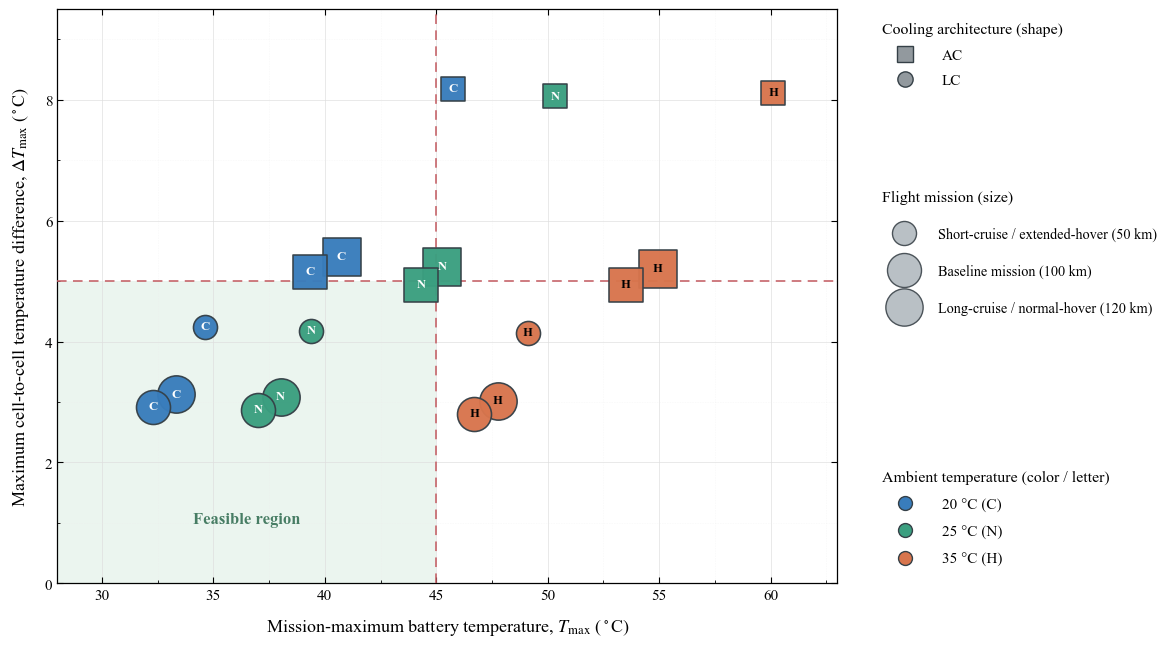

PNG: D:\eBATS\out\C0010\C0010R00_PARK25_ACLC_INTG_CFD_CMP_thermal_feasibility.png
PDF: D:\eBATS\out\C0010\C0010R00_PARK25_ACLC_INTG_CFD_CMP_thermal_feasibility.pdf
Feasible cases: 7 / 18
Mission marker areas (pt^2): {'Short-cruise / extended-hover (50 km)': 300.0, 'Baseline mission (100 km)': 600.0, 'Long-cruise / normal-hover (120 km)': 720.0}


In [8]:

# =============================================================================
# Figure 17 | Thermal feasibility map
# Available CFD conditions: empty LC 100-km 20/35-C cases are skipped
# =============================================================================

# =============================================================================
# 1. Import libraries and define plot settings
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import AutoMinorLocator

FIGURE_NAME = 'C0010R00_PARK25_ACLC_INTG_CFD_CMP_thermal_feasibility'
OUT_DIR = Path(r'D:\eBATS\out\C0010')
PAPER_IMAGE_DIR = Path(r'D:\Workspace\Paper_eBATS\images')
DPI = 900

# Thermal design constraints
T_LIMIT = 45.0
DT_LIMIT = 5.0

# Cooling architectures
COOLING_ORDER = ('AC', 'LC')
COOLING_MARKERS = {'AC': 's', 'LC': 'o'}

# Flight missions
MISSION_ORDER = (
    'Short-cruise / extended-hover (50 km)',
    'Baseline mission (100 km)',
    'Long-cruise / normal-hover (120 km)'
)

MISSION_KM = {
    MISSION_ORDER[0]: 50,
    MISSION_ORDER[1]: 100,
    MISSION_ORDER[2]: 120
}

# Marker area is proportional to the flight distance
AREA_PER_KM = 6.0
MISSION_AREA = {name: km * AREA_PER_KM for name, km in MISSION_KM.items()}

# Ambient temperatures
AMBIENT_ORDER = (20, 25, 35)

AMBIENT_COLORS = {
    20: '#397DBC',
    25: '#3B9F80',
    35: '#D8754D'
}

AMBIENT_LETTERS = {
    20: 'C',
    25: 'N',
    35: 'H'
}

AMBIENT_TEXT_COLORS = {
    20: 'white',
    25: 'white',
    35: 'black'
}

# Plot colors
FEASIBLE_COLOR = '#CDE7D9'
CONSTRAINT_COLOR = '#C45E64'
EDGE_COLOR = '#354047'

# Legend layout
LEGEND_LEFT = 0.72
LEGEND_HANDLE_LENGTH = 3.0

# =============================================================================
# 2. Load and check available CFD conditions
# =============================================================================

if 'df_fig17' in globals():
    df = df_fig17.copy()
elif 'results' in globals():
    df = pd.DataFrame(results)
else:
    raise RuntimeError('Please run the Figure 17 data cell first.')

required_columns = ['Cooling', 'Mission', 'Ambient_C', 'Tmax_C', 'DTmax_C']

for column in required_columns:
    if column not in df.columns:
        raise KeyError(f'Missing column: {column}')

if 'EXPECTED_LOADED_KEYS' not in globals():
    raise RuntimeError('Run the Figure 17 CFD data cell first.')
if len(df) != len(EXPECTED_LOADED_KEYS):
    raise ValueError(f'Expected {len(EXPECTED_LOADED_KEYS)} CFD conditions, found {len(df)}')
actual_keys = set(zip(df['Cooling'], df['Mission'], df['Ambient_C']))
if actual_keys != EXPECTED_LOADED_KEYS or set(df['Source']) != {'CFD'}:
    raise ValueError('Figure 17 must contain exactly the available CFD conditions.')

if df.duplicated(subset=['Cooling', 'Mission', 'Ambient_C']).any():
    raise ValueError('Duplicate operating conditions detected.')

if set(df['Cooling']) != set(COOLING_ORDER):
    raise ValueError('Unexpected cooling architecture labels.')

if set(df['Mission']) != set(MISSION_ORDER):
    raise ValueError('Unexpected mission labels.')

df['Ambient_C'] = pd.to_numeric(df['Ambient_C'], errors='raise').astype(int)
df['Tmax_C'] = pd.to_numeric(df['Tmax_C'], errors='raise')
df['DTmax_C'] = pd.to_numeric(df['DTmax_C'], errors='raise')

if not np.isfinite(df[['Tmax_C', 'DTmax_C']].to_numpy()).all():
    raise ValueError('Temperature data contain non-finite values.')

if set(df['Ambient_C']) != set(AMBIENT_ORDER):
    raise ValueError('Ambient temperatures must be 20, 25 and 35 C.')

df['Feasible'] = (df['Tmax_C'] <= T_LIMIT) & (df['DTmax_C'] <= DT_LIMIT)
df['Marker_area'] = df['Mission'].map(MISSION_AREA)

# =============================================================================
# 3. Set scientific plotting style
# =============================================================================

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'mathtext.fontset': 'stix',
    'font.size': 12,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'axes.linewidth': 0.9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'axes.unicode_minus': False,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

# =============================================================================
# 4. Create figure and coordinate system
# =============================================================================

plt.close('all')

fig = plt.figure(figsize=(13.0, 7.0))
ax = fig.add_axes([0.09, 0.13, 0.60, 0.82])

xmin = min(28.0, float(np.floor(df['Tmax_C'].min() - 2.0)))
xmax = max(63.0, float(np.ceil(df['Tmax_C'].max() + 2.0)))
ymax = max(9.5, float(np.ceil(df['DTmax_C'].max() + 0.8)))

ax.set_xlim(xmin, xmax)
ax.set_ylim(0.0, ymax)

# =============================================================================
# 5. Draw thermal feasibility region and design constraints
# =============================================================================

# 5.1 Feasible region
ax.add_patch(Rectangle((xmin, 0.0), T_LIMIT - xmin, DT_LIMIT, facecolor=FEASIBLE_COLOR, edgecolor='none', alpha=0.40, zorder=0))

# 5.2 Maximum temperature constraint
ax.axvline(T_LIMIT, color=CONSTRAINT_COLOR, linewidth=1.15, linestyle=(0, (6, 4)), zorder=3)

# 5.3 Maximum temperature difference constraint
ax.axhline(DT_LIMIT, color=CONSTRAINT_COLOR, linewidth=1.15, linestyle=(0, (6, 4)), zorder=3)

# 5.4 Feasible-region label
ax.text((xmin + T_LIMIT) / 2, 1.05, 'Feasible region', color='#477D64', fontsize=12, fontweight='bold', ha='center', va='center', zorder=2)

# =============================================================================
# 6. Plot all operating conditions
# =============================================================================

# Draw larger markers first to maintain visibility
plot_df = df.sort_values('Marker_area', ascending=False)

for _, item in plot_df.iterrows():

    x = float(item['Tmax_C'])
    y = float(item['DTmax_C'])

    ambient = int(item['Ambient_C'])
    cooling = item['Cooling']
    mission = item['Mission']

    # 6.1 Marker shape, color and size
    ax.scatter(x, y, s=MISSION_AREA[mission], marker=COOLING_MARKERS[cooling], facecolors=AMBIENT_COLORS[ambient], edgecolors=EDGE_COLOR, linewidths=1.15, alpha=0.97, zorder=5)

    # 6.2 Ambient-temperature letter
    ax.annotate(AMBIENT_LETTERS[ambient], xy=(x, y), xytext=(0, 0), textcoords='offset points', ha='center', va='center', fontsize=9.2, fontweight='bold', color=AMBIENT_TEXT_COLORS[ambient], zorder=6)

# =============================================================================
# 7. Set axes, ticks and grids
# =============================================================================

# 7.1 Axis labels
ax.set_xlabel(r'Mission-maximum battery temperature, $T_{\max}$ ($^\circ$C)', labelpad=10)
ax.set_ylabel(r'Maximum cell-to-cell temperature difference, $\Delta T_{\max}$ ($^\circ$C)', labelpad=10)

# 7.2 Minor ticks
ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.yaxis.set_minor_locator(AutoMinorLocator(2))

# 7.3 Grid lines
ax.grid(which='major', color='0.87', linewidth=0.65, linestyle='-', alpha=0.72)
ax.grid(which='minor', color='0.92', linewidth=0.45, linestyle=':', alpha=0.52)

# 7.4 Axes appearance
ax.set_axisbelow(True)
ax.tick_params(axis='both', direction='in', top=True, right=True)

# =============================================================================
# 8. Define a left-aligned legend helper
# =============================================================================

def align_legend_left(legend):
    legend._legend_box.align = 'left'
    legend.get_title().set_ha('left')
    return legend

# =============================================================================
# 9. Legend 1 - Cooling architecture
# =============================================================================

cooling_handles = [
    Line2D([0], [0], marker='s', linestyle='none', markersize=11, markerfacecolor='#92999E', markeredgecolor=EDGE_COLOR, label='AC'),
    Line2D([0], [0], marker='o', linestyle='none', markersize=11, markerfacecolor='#92999E', markeredgecolor=EDGE_COLOR, label='LC')
]

legend_cooling = fig.legend(
    handles=cooling_handles,
    title='Cooling architecture (shape)',
    loc='upper left',
    bbox_to_anchor=(LEGEND_LEFT, 0.94),
    frameon=False,
    fontsize=11,
    title_fontsize=11.5,
    labelspacing=0.75,
    handlelength=LEGEND_HANDLE_LENGTH,
    handletextpad=0.9,
    borderaxespad=0.0
)

align_legend_left(legend_cooling)

# =============================================================================
# 10. Legend 2 - Flight mission
# =============================================================================

mission_handles = [
    Line2D([0], [0], marker='o', linestyle='none', markersize=np.sqrt(MISSION_AREA[mission]), markerfacecolor='#B9C0C5', markeredgecolor='#4B5359', label=mission)
    for mission in MISSION_ORDER
]

legend_mission = fig.legend(
    handles=mission_handles,
    title='Flight mission (size)',
    loc='upper left',
    bbox_to_anchor=(LEGEND_LEFT, 0.70),
    frameon=False,
    fontsize=10.3,
    title_fontsize=11.5,
    labelspacing=1.6,
    handlelength=LEGEND_HANDLE_LENGTH,
    handletextpad=0.9,
    borderaxespad=0.0
)

align_legend_left(legend_mission)

# =============================================================================
# 11. Legend 3 - Ambient temperature
# =============================================================================

ambient_handles = [
    Line2D([0], [0], marker='o', linestyle='none', markersize=10, markerfacecolor=AMBIENT_COLORS[t], markeredgecolor=EDGE_COLOR, label=f'{t} °C ({AMBIENT_LETTERS[t]})')
    for t in AMBIENT_ORDER
]

legend_ambient = fig.legend(
    handles=ambient_handles,
    title='Ambient temperature (color / letter)',
    loc='upper left',
    bbox_to_anchor=(LEGEND_LEFT, 0.30),
    frameon=False,
    fontsize=11,
    title_fontsize=11.5,
    labelspacing=0.85,
    handlelength=LEGEND_HANDLE_LENGTH,
    handletextpad=0.9,
    borderaxespad=0.0
)

align_legend_left(legend_ambient)

# =============================================================================
# 12. Export figure
# =============================================================================

OUT_DIR.mkdir(parents=True, exist_ok=True)

PNG_FILE = OUT_DIR / f'{FIGURE_NAME}.png'
PDF_FILE = OUT_DIR / f'{FIGURE_NAME}.pdf'

fig.savefig(PNG_FILE, dpi=DPI, bbox_inches='tight', facecolor='white')
fig.savefig(PDF_FILE, bbox_inches='tight', facecolor='white')

if PAPER_IMAGE_DIR.is_dir():
    fig.savefig(PAPER_IMAGE_DIR / f'{FIGURE_NAME}.pdf', bbox_inches='tight', facecolor='white')

plt.show()

# =============================================================================
# 13. Print results
# =============================================================================

print('PNG:', PNG_FILE)
print('PDF:', PDF_FILE)
print(f'Feasible cases: {int(df["Feasible"].sum())} / {len(df)}')
print('Mission marker areas (pt^2):', MISSION_AREA)
